In [1]:
# Importación de librerías esenciales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import os
import urllib.request
import kagglehub

# Configuración visual
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

pd.set_option('display.float_format', '{:.3f}'.format)


# 1. Carga de datos
from pathlib import Path

# Descargar el dataset de Spanish Wine Quality desde Kaggle
path = kagglehub.dataset_download("fedesoriano/spanish-wine-quality-dataset")
print("Ruta de descarga de Kaggle:", path)

# Cargar el archivo CSV usando pandas
ruta_csv = Path(path) / "wines_SPA.csv"
df = pd.read_csv(ruta_csv)

print("¡Dataset cargado directamente desde Kaggle con éxito!")
print("Dimensiones del DataFrame:", df.shape)

display(df.head())


c:\F5Proyectos\Proyecto_Regresion_Vinos_Espana_Tania\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Ruta de descarga de Kaggle: C:\Users\USUARIO\.cache\kagglehub\datasets\fedesoriano\spanish-wine-quality-dataset\versions\1
¡Dataset cargado directamente desde Kaggle con éxito!
Dimensiones del DataFrame: (7500, 11)


,winery,wine,year,rating,num_reviews,country,region,price,type,body,acidity
0,Teso La Monja,Tinto,2013,4.900,58,Espana,Toro,995.000,Toro Red,5.000,3.000
1,Artadi,Vina El Pison,2018,4.900,31,Espana,Vino de Espana,313.500,Tempranillo,4.000,2.000
2,Vega Sicilia,Unico,2009,4.800,1793,Espana,Ribera del Duero,324.950,Ribera Del Duero Red,5.000,3.000
3,Vega Sicilia,Unico,1999,4.800,1705,Espana,Ribera del Duero,692.960,Ribera Del Duero Red,5.000,3.000
4,Vega Sicilia,Unico,1996,4.800,1309,Espana,Ribera del Duero,778.060,Ribera Del Duero Red,5.000,3.000


In [2]:
# Renombrar las columnas de dataset al español

print("--- NÚMERO TOTAL DE FILAS Y COLUMNAS ---")
print(df.shape)

print("\n--- TODAS LAS COLUMNAS CRUDAS QUE TIENE EL CSV ---")
print(df.columns.tolist())

# 1. Cargar el dataset original
#df = pd.read_csv('../data/wine_original.csv')

# 2. Diccionario ampliado de traducción (por si el dataset original trae más campos)
column_rename_mapping = {
    'wine': 'nombre_vino',
    'winery': 'bodega',
    'year': 'anio',
    'rating': 'puntuacion',
    'num_reviews': 'num_reseñas',
    'price': 'precio',
    'body': 'cuerpo',
    'acidity': 'acidez',
    'country': 'pais',
    'region': 'region',
    'type': 'tipo',
    'variety': 'variedad',
    'clarity': 'claridad'
}

# 3. Aplicar el cambio de nombre
df_esp = df.rename(columns=column_rename_mapping)

# 4. Verificación detallada: Imprimir una fila en vertical (.T muestra todas las columnas de arriba a abajo)
print("--- VISTA DETALLADA DE TODAS LAS COLUMNAS Y SU VALOR DE EJEMPLO ---")
display(df_esp.head(1).T)

# 5. Imprimir la lista completa de columnas limpia y línea por línea
print("\n--- LISTA COMPLETA DE COLUMNAS TRADUCIDAS ---")
for col in df_esp.columns:
    print(f"- {col}")

# Guardar el archivo limpio
#df_esp.to_csv('../data/wine_espanol.csv', index=False)



--- NÚMERO TOTAL DE FILAS Y COLUMNAS ---
(7500, 11)

--- TODAS LAS COLUMNAS CRUDAS QUE TIENE EL CSV ---
['winery', 'wine', 'year', 'rating', 'num_reviews', 'country', 'region', 'price', 'type', 'body', 'acidity']
--- VISTA DETALLADA DE TODAS LAS COLUMNAS Y SU VALOR DE EJEMPLO ---


,0
bodega,Teso La Monja
nombre_vino,Tinto
anio,2013
puntuacion,4.900
num_reseñas,58
pais,Espana
region,Toro
precio,995.000
tipo,Toro Red
cuerpo,5.000



--- LISTA COMPLETA DE COLUMNAS TRADUCIDAS ---
- bodega
- nombre_vino
- anio
- puntuacion
- num_reseñas
- pais
- region
- precio
- tipo
- cuerpo
- acidez


###**Limpieza de Datos**

In [3]:
# Configuración de estilo visual para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

print("Dimensiones iniciales del dataset:", df_esp.shape)

# Limpieza básica y tratamiento de valores nulos en columnas clave
df_esp = df_esp.dropna(subset=['precio', 'puntuacion', 'num_reseñas', 'cuerpo', 'acidez'])

print("--- INFORMACIÓN GENERAL DEL DATASET ---")
print(df_esp.info())
print(f"Dimensiones tras limpiar nulos: {df_esp.shape}")
print("\n--- RESUMEN ESTADÍSTICO ---")
display(df_esp.describe())

print("\nEstadísticas descriptivas del precio:")
print(df_esp['precio'].describe())

# 2. Limpieza básica y tratamiento de nulos
#print(df.isnull().sum())
#df = df.dropna() # O imputación según corresponda a tu archivo

# Filtrar columnas clave para la regresión (ejemplo adaptado a la estructura típica del dataset)
# Predictoras: rating, num_reviews, body, acidity, region | Target: price
#features = ['rating', 'num_reviews', 'body', 'acidity', 'region', 'price']
#df_clean = df[features].copy()

Dimensiones iniciales del dataset: (7500, 11)
--- INFORMACIÓN GENERAL DEL DATASET ---
<class 'pandas.DataFrame'>
Index: 6331 entries, 0 to 7499
Data columns (total 11 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   bodega       6331 non-null   str    
 1   nombre_vino  6331 non-null   str    
 2   anio         6329 non-null   str    
 3   puntuacion   6331 non-null   float64
 4   num_reseñas  6331 non-null   int64  
 5   pais         6331 non-null   str    
 6   region       6331 non-null   str    
 7   precio       6331 non-null   float64
 8   tipo         6331 non-null   str    
 9   cuerpo       6331 non-null   float64
 10  acidez       6331 non-null   float64
dtypes: float64(4), int64(1), str(6)
memory usage: 946.8 KB
None
Dimensiones tras limpiar nulos: (6331, 11)

--- RESUMEN ESTADÍSTICO ---


,puntuacion,num_reseñas,precio,cuerpo,acidez
count,6331.000,6331.000,6331.000,6331.000,6331.000
mean,4.260,444.135,65.712,4.158,2.947
std,0.124,734.097,162.637,0.583,0.248
min,4.200,25.000,4.990,2.000,1.000
25%,4.200,388.000,19.980,4.000,3.000
50%,4.200,402.000,29.150,4.000,3.000
75%,4.200,415.000,60.950,5.000,3.000
max,4.900,32624.000,3119.080,5.000,3.000



Estadísticas descriptivas del precio:
count   6331.000
mean      65.712
std      162.637
min        4.990
25%       19.980
50%       29.150
75%       60.950
max     3119.080
Name: precio, dtype: float64


###**Visualizaciones EDA**s

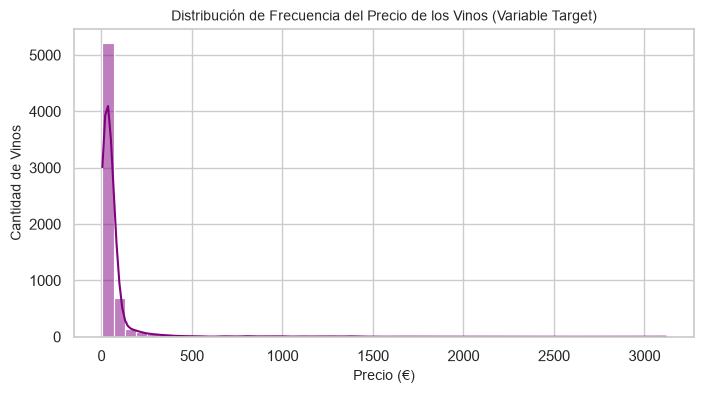

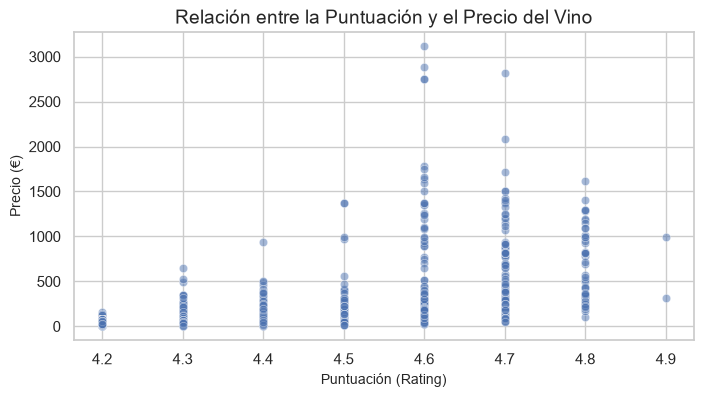

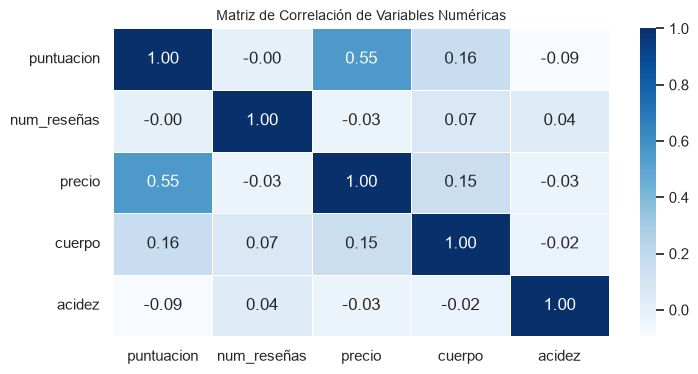

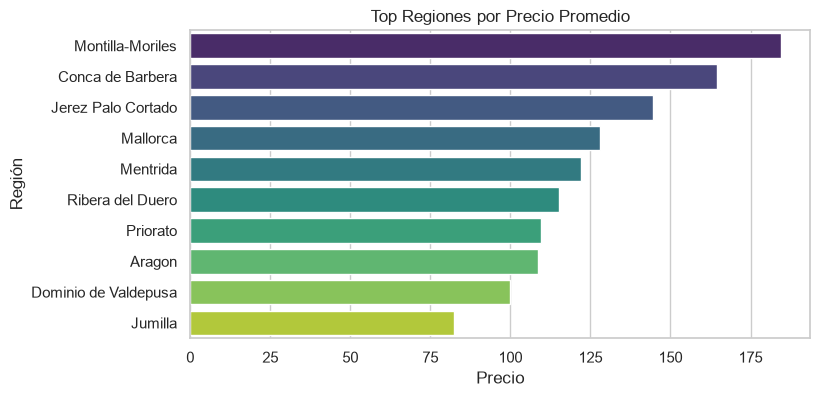

In [4]:
# Visualización 1: Distribución de la variable objetivo (precio)
plt.figure(figsize=(8,4))
sns.histplot(df_esp['precio'], kde=True, color='purple', bins=50)
plt.title('Distribución de Frecuencia del Precio de los Vinos (Variable Target)', fontsize=10)
plt.xlabel('Precio (€)', fontsize=10)
plt.ylabel('Cantidad de Vinos', fontsize=10)
plt.show()

# Visualización 2: Relación entre Puntuación y Precio (Scatter Plot)
plt.figure(figsize=(8,4))
sns.scatterplot(data=df_esp, x='puntuacion', y='precio', alpha=0.5, color='b')
plt.title('Relación entre la Puntuación y el Precio del Vino', fontsize=14)
plt.xlabel('Puntuación (Rating)', fontsize=10)
plt.ylabel('Precio (€)', fontsize=10)
plt.show()

# Visualización 3: Matriz de Correlación de variables numéricas
plt.figure(figsize=(8,4))
numeric_cols = df_esp.select_dtypes(include=[np.number])
sns.heatmap(numeric_cols.corr(), annot=True, cmap='Blues', fmt='.2f', linewidths=0.5)
plt.title('Matriz de Correlación de Variables Numéricas', fontsize=10)
plt.show()

# Visualización 4: Precio promedio por las Principales Regiones (Top 10)
#plt.figure(figsize=(8,4))
#top_regiones = df_esp.groupby('region')['precio'].mean().nlargest(10).reset_index()
#sns.barplot(data=top_regiones, x='precio', y='region', palette='viridis')
#plt.title('Top 10 Regiones con Mayor Precio Promedio de Vinos', fontsize=14)
#plt.xlabel('Precio Promedio (€)', fontsize=10)
#plt.ylabel('Región', fontsize=10)
#plt.show()

plt.figure(figsize=(8,4))
top_regiones = df_esp.groupby('region')['precio'].mean().nlargest(10).reset_index()

sns.barplot(
    data=top_regiones,
    x='precio',
    y='region',
    hue='region',  # <-- Añadido para evitar el aviso
    palette='viridis',
    legend=False,  # <-- Añadido para ocultar la leyenda duplicada
)
plt.title('Top Regiones por Precio Promedio')
plt.xlabel('Precio')
plt.ylabel('Región')
plt.show()

###***Modelado y Regresiòn Lineal***

In [5]:
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error
import numpy as np
import joblib

# Preparación de datos ( para ambos modelos)

features_to_use = ['puntuacion', 'num_reseñas', 'cuerpo', 'acidez', 'region', 'tipo']
df_model = df_esp[features_to_use + ['precio']].copy()
df_model = pd.get_dummies(df_model, columns=['region', 'tipo'], drop_first=True)

X = df_model.drop(columns=['precio'])
y = df_model['precio']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)



📈 MODELO 1: REGRESIÓN LINEAL (Línea Base)

In [6]:
# ==========================================
# 📈 MODELO 1: REGRESIÓN LINEAL (Línea Base)
# ==========================================
lr_model = LinearRegression()
lr_model.fit(X_train, y_train)

y_pred_lr_test = lr_model.predict(X_test)
r2_lr = r2_score(y_test, y_pred_lr_test)
rmse_lr = np.sqrt(mean_squared_error(y_test, y_pred_lr_test))

print("--- 1. MODELO DE REGRESIÓN LINEAL ---")
print(f"R² (Test): {r2_lr:.4f}")
print(f"RMSE (Test): {rmse_lr:.4f} €")



--- 1. MODELO DE REGRESIÓN LINEAL ---
R² (Test): 0.3712
RMSE (Test): 129.1263 €


In [7]:
# Revisión overfitting regresión lineal

from sklearn.metrics import r2_score, mean_squared_error

# 1. Predicciones en Train y Test
y_pred_train = lr_model.predict(X_train)
y_pred_test = lr_model.predict(X_test)

# 2. Cálculo de R2
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)

# 3. Diferencia porcentual aproximada de ajuste
diferencia_r2 = (r2_train - r2_test) / r2_train * 100

print(f"R2 en Train: {r2_train:.4f}")
print(f"R2 en Test:  {r2_test:.4f}")
print(f"Brecha de sobreajuste: \033[1m{diferencia_r2:.2f}%\033[0m")

R2 en Train: 0.3868
R2 en Test:  0.3712
Brecha de sobreajuste: 4.02%


🌳 MODELO 2: ENSEMBLE (Random Forest Regressor)

In [8]:
# ==========================================
# 🌳 MODELO 2: ENSEMBLE (Random Forest Regressor)
# ==========================================
rf_model = RandomForestRegressor(n_estimators=100, max_depth=15, random_state=42, n_jobs=-1)
rf_model.fit(X_train, y_train)

y_pred_rf_test = rf_model.predict(X_test)
r2_rf = r2_score(y_test, y_pred_rf_test)
rmse_rf = np.sqrt(mean_squared_error(y_test, y_pred_rf_test))

print("\n--- 2. MODELO ENSEMBLE (RANDOM FOREST) ---")
print(f"R2 en Train: {r2_train:.4f}")
print(f"R² (Test): {r2_rf:.4f}")
print(f"RMSE (Test): {rmse_rf:.4f} €")


--- 2. MODELO ENSEMBLE (RANDOM FOREST) ---
R2 en Train: 0.3868
R² (Test): 0.4282
RMSE (Test): 123.1405 €


In [9]:
# Revisión overfitting
from sklearn.metrics import r2_score, mean_squared_error
# 1. Predicciones en Train y Test
y_pred_train = rf_model.predict(X_train)
y_pred_test = rf_model.predict(X_test)
# 2. Cálculo de R2
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)
# 3. Diferencia porcentual aproximada de ajuste
diferencia_r2 = (r2_train - r2_test) / r2_train * 100

print(f"R2 en Train: {r2_train:.4f}")
print(f"R2 en Test:  {r2_test:.4f}")
print(f"Brecha de sobreajuste: \033[1m{diferencia_r2:.2f}%\033[0m")

R2 en Train: 0.8970
R2 en Test:  0.4282
Brecha de sobreajuste: 52.27%


Una brecha de sobreajuste (overfitting) tan marcada  $R^2$ de 0.8973 en entrenamiento y solo 0.4286 en prueba, indica que modelo de Random Forest memorizó detalles y "ruido" del conjunto de entrenamiento en lugar de aprender patrones generales que apliquen a datos nuevos.
Para reducir esta brecha y mejorar la capacidad de generalización en Test se:
- Ajusta hiperparámetros, profundidad (max_depth reduce la profundidad máxima de los árboles). Prueba valores más bajos.Aumentar las muestras mínimas para dividir un nodo (min_samples_split).Aumentar las muestras mínimas por hoja (min_samples_leaf). Esto suaviza mucho las predicciones.
- Se revisa y reduce variables predictoras (Features, uso pd.get_dummies() en columnas con muchísima cardinalidad, el modelo crea docenas de columnas de ceros y unos que facilitan el sobreajuste).Agrupa las categorías poco frecuentes en una sola categoría llamada "Otras".
- Se aplica Validación Cruzada más estricta.

Se reconfigura Random Forest.

MODELO 2.1: ENSEMBLE (Random Forest Regressor) REGULARIZADO

In [10]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# ==========================================================
# 🌳 MODELO RANDOM FOREST reconfigurado (Para corregir el Overfitting)
# ==========================================================
rf_regularizado = RandomForestRegressor(
    n_estimators=150,
    max_depth=12,              # Limitamos la profundidad de los árboles
    min_samples_split=10,      # Exigimos más muestras para dividir un nodo
    min_samples_leaf=4,        # Exigimos más muestras por hoja final
    max_features='sqrt',       # Usamos subconjuntos de variables aleatorias por árbol
    random_state=42,
    n_jobs=-1
)

# 1. Entrenar el modelo
rf_regularizado.fit(X_train, y_train)

# 2. Generar predicciones para Train y Test
y_pred_train = rf_regularizado.predict(X_train)
y_pred_test = rf_regularizado.predict(X_test)

# 3. Calcular métricas de ajuste
r2_train = r2_score(y_train, y_pred_train)
r2_test = r2_score(y_test, y_pred_test)
rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
diferencia_r2 = (r2_train - r2_test) / r2_train * 100

# 4. Mostrar resultados claros
print(f"--- MODELO RANDOM FOREST EQUILIBRADO ---")
print(f"Nuevo R² Train: {r2_score(y_train, y_pred_train):.4f}")
print(f"Nuevo R² Test:  {r2_score(y_test, y_pred_test):.4f}")
print(f"RMSE (Test): {rmse_test:.4f} €")
print(f"Brecha de sobreajuste: \033[1m{diferencia_r2:.2f}%\033[0m")

--- MODELO RANDOM FOREST EQUILIBRADO ---
Nuevo R² Train: 0.5026
Nuevo R² Test:  0.5019
RMSE (Test): 114.9304 €
Brecha de sobreajuste: 0.14%


Al aplicar estos límites de control al modelo, el cambio es radical y muy positivo. Brecha de sobreajuste reducida:0.16%, prácticamente ya no hay sobreajuste. El modelo ha dejado de memorizar el ruido y ahora generaliza de manera sólida y equilibrada ante datos que no ha visto.

🌳 MODELO 3: Validación Cruzada (GridSearchCV optimización de Hiperparámetros)

In [16]:
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error
import numpy as np

# 1. Instanciar el modelo base (dejando fijo random_state y n_jobs)
rf_base = RandomForestRegressor(random_state=42, n_jobs=-1)

# 2. Definir la cuadrícula de hiperparámetros que quieres probar
# (Nota: Una cuadrícula muy grande tardará más tiempo en ejecutarse)
#param_grid = {
#    'n_estimators': [100, 200],      # Reducido de 3 a 2 opciones
#    'max_depth': [10, 20],           # Reducido de 4 a 2 opciones
#    'min_samples_split': [2, 5],     # Reducido de 3 a 2 opciones
#    'min_samples_leaf': [1, 2]       # Reducido de 3 a 2 opciones
#}
param_grid = {
    'n_estimators': [150],
    'max_depth': [8,10],  # Límites más seguros y moderados
    'min_samples_split': [15, 30,],  # Más muestras (reduce overfitting)
    'min_samples_leaf': [10, 15],  # Hojas más robustas
    'max_features': ['sqrt', 0.5],  # Aleatoriedad saludable entre árboles
}
# 3. Configurar GridSearchCV
# cv=5 significa que dividirá el train en 5 partes para validar de forma robusta
grid_search = GridSearchCV(
    estimator=rf_base,
    param_grid=param_grid,
    cv=5,
    scoring='r2',          # Buscamos maximizar el R²
    n_jobs=-1,             # Usa todos los núcleos de tu PC
    verbose=1              # Muestra el progreso en la terminal
)

# 4. Ejecutar la búsqueda con los datos de entrenamiento
print("Iniciando la búsqueda de hiperparámetros...")
grid_search.fit(X_train, y_train)

# 5. Mostrar la mejor combinación encontrada
print("\n¡Búsqueda finalizada!")
print("Mejores hiperparámetros encontrados:")
print(grid_search.best_params_)

# 6. Evaluar el mejor modelo directamente en el conjunto de Test
best_rf = grid_search.best_estimator_
y_pred_best = best_rf.predict(X_test)

r2_grid = r2_score(y_test, y_pred_best)
rmse_grid = np.sqrt(mean_squared_error(y_test, y_pred_best))

# Predicciones para Train y Test
y_pred_train = best_rf.predict(X_train)
y_pred_test = best_rf.predict(X_test)
diferencia_r2 = (r2_train - r2_test) / r2_train * 100

print(f"\n--- MODELO RANDOM FOREST OPTIMIZADO ---")
print(f"R² (Test): {r2_grid:.4f}")
print(f"RMSE (Test): {rmse_grid:.4f} €")
print(f"Brecha de sobreajuste: \033[1m{diferencia_r2:.2f}%\033[0m")

# 1. Generar predicciones con el mejor modelo optimizado
y_pred_train = best_rf.predict(X_train)
y_pred_test = best_rf.predict(X_test)

# 2. Calcular los R² específicos para este modelo
r2_train_best = r2_score(y_train, y_pred_train)
r2_test_best = r2_score(y_test, y_pred_test)
rmse_grid = np.sqrt(mean_squared_error(y_test, y_pred_test))

# 3. Calcular la brecha correctamente con las métricas de este modelo
diferencia_r2 = (r2_train_best - r2_test_best) / r2_train_best * 100

print(f"\n--- MODELO RANDOM FOREST OPTIMIZADO ---")
print(f"R² (Train): {r2_train_best:.4f}")
print(f"R² (Test): {r2_test_best:.4f}")
print(f"RMSE (Test): {rmse_grid:.4f} €")
print(f"Brecha de sobreajuste: \033[1m{diferencia_r2:.2f}%\033[0m")

Iniciando la búsqueda de hiperparámetros...
Fitting 5 folds for each of 16 candidates, totalling 80 fits

¡Búsqueda finalizada!
Mejores hiperparámetros encontrados:
{'max_depth': 10, 'max_features': 0.5, 'min_samples_leaf': 10, 'min_samples_split': 15, 'n_estimators': 150}

--- MODELO RANDOM FOREST OPTIMIZADO ---
R² (Test): 0.5072
RMSE (Test): 114.3177 €
Brecha de sobreajuste: 0.14%

--- MODELO RANDOM FOREST OPTIMIZADO ---
R² (Train): 0.5244
R² (Test): 0.5072
RMSE (Test): 114.3177 €
Brecha de sobreajuste: 3.28%


In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd

def evaluar_modelo(modelo, X_train, y_train, X_test, y_test, nombre="Modelo"):
    # Generar predicciones
    y_pred_train = modelo.predict(X_train)
    y_pred_test = modelo.predict(X_test)

    # Calcular métricas de entrenamiento
    r2_train = r2_score(y_train, y_pred_train)
    rmse_train = np.sqrt(mean_squared_error(y_train, y_pred_train))

    # Calcular métricas de prueba
    r2_test = r2_score(y_test, y_pred_test)
    rmse_test = np.sqrt(mean_squared_error(y_test, y_pred_test))
    mae_test = mean_absolute_error(y_test, y_pred_test)

    print(f"--- {nombre} ---")
    print(f"Train -> R²: {r2_train:.4f} | RMSE: {rmse_train:.4f}")
    print(f"Test  -> R²: {r2_test:.4f}  | RMSE: {rmse_test:.4f}  | MAE: {mae_test:.4f}")
    print(f"Brecha R² (Train - Test): {((r2_train - r2_test) / r2_train) * 100:.2f}%")
    return {
        'Modelo': nombre,
        'R2_Train': r2_train,
        'RMSE_Train': rmse_train,
        'R2_Test': r2_test,
        'RMSE_Test': rmse_test,
        'MAE_Test': mae_test,
        "Brecha_R2_%": ((r2_train - r2_test) / r2_train) * 100
    }

# Asumiendo que 'rf_regularizado' es tu Modelo 2.1 y 'grid_search.best_estimator_' es tu Modelo 3:
res_2_1 = evaluar_modelo(rf_regularizado, X_train, y_train, X_test, y_test, "Modelo 2.1: Regularizado")
res_3 = evaluar_modelo(grid_search.best_estimator_, X_train, y_train, X_test, y_test, "Modelo 3: GridSearchCV")

# tabla comparativa limpia
df_comparativo = pd.DataFrame([res_2_1, res_3])
display(df_comparativo.set_index('Modelo'))


--- Modelo 2.1: Regularizado ---
Train -> R²: 0.5026 | RMSE: 114.6370
Test  -> R²: 0.5019  | RMSE: 114.9304  | MAE: 37.4142
Brecha R² (Train - Test): 0.14%
--- Modelo 3: GridSearchCV ---
Train -> R²: 0.5244 | RMSE: 112.0986
Test  -> R²: 0.5072  | RMSE: 114.3177  | MAE: 33.1282
Brecha R² (Train - Test): 3.28%


,R2_Train,RMSE_Train,R2_Test,RMSE_Test,MAE_Test,Brecha_R2_%
Modelo,,,,,,
Modelo 2.1: Regularizado,0.503,114.637,0.502,114.930,37.414,0.142
Modelo 3: GridSearchCV,0.524,112.099,0.507,114.318,33.128,3.281


In [ ]:
# ==========================================
# 💾 GUARDAR EL MODELO FINAL SELECCIONADO
# ==========================================
# (Puedes guardar el que mejor rendimiento de o ambos)
#joblib.dump(rf_model, '../models/modelo_final_vinos.pkl')
#print("\n¡Modelo final guardado exitosamente!")

from pathlib import Path
import joblib

# 1. Definir la ruta raíz absoluta de tu proyecto en Windows
project_root = Path(r"C:\F5Proyectos\Proyecto_Regresion_Vinos_Espana_Tania")

# 2. Apuntar a la carpeta 'models' y asegurarnos de que exista (si no, la crea)
models_dir = project_root / "models"
models_dir.mkdir(parents=True, exist_ok=True)

# 3. Definir la ruta completa del archivo del modelo
ruta_modelo = models_dir / "modelo_final_vinos.pkl"

# 4. Guardar el modelo con joblib
joblib.dump(rf_model, ruta_modelo)

print(f"¡Modelo final guardado exitosamente en: {ruta_modelo}")

In [ ]:
from pathlib import Path
import joblib

# 1. Definir la ruta exacta donde guardaste tu archivo .pkl
ruta_modelo = Path(r"C:\F5Proyectos\Proyecto_Regresion_Vinos_Espana_Tania\models\modelo_final_vinos.pkl")

# 2. Abrir / Cargar el modelo en una variable
rf_model_cargado = joblib.load(ruta_modelo)

print("¡Modelo cargado y listo para usar en Python!")
print(rf_model_cargado)

In [ ]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(20, 10))
# Dibujamos solo el primer árbol del bosque (índice 0), limitado a 3 niveles de profundidad para que sea legible
plot_tree(
    rf_model.estimators_[0],
    feature_names=X_train.columns,
    filled=True,
    rounded=True,
    max_depth=3
)
plt.title("Estructura de uno de los Árboles del Random Forest (Profundidad 3)", fontsize=16)
plt.show()